[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Dataset Shape: (3000, 3)
Columns: ['Coments', 'Emotion', 'Sentiment']


,Coments,Emotion,Sentiment
0,أداء يفرّح القلب وفخر لكل أردني,Pride,Positive
1,منتخبا الثاني ‏‪ الف تحية من سوريا إلى النشامى...,Pride,Positive
2,أداء يفرّح القلب وفخر لكل أردني,Pride,Positive
3,بصراحه الاردن واليابان لأن اقوى منتخبين في آسي...,Pride,Positive
4,نشكر كل من قام بواجبه العربي بالفرح للمنتخب ال...,Pride,Positive



Duplicates removed: 89

Before Cleaning:
أداء يفرّح القلب وفخر لكل أردني

After Cleaning:
اداء يفرح القلب وفخر لكل اردني

Class Distribution:


,Count,Percentage (%)
Class,,
Pride,1741,59.81
Anger,652,22.40
Neutral,518,17.79


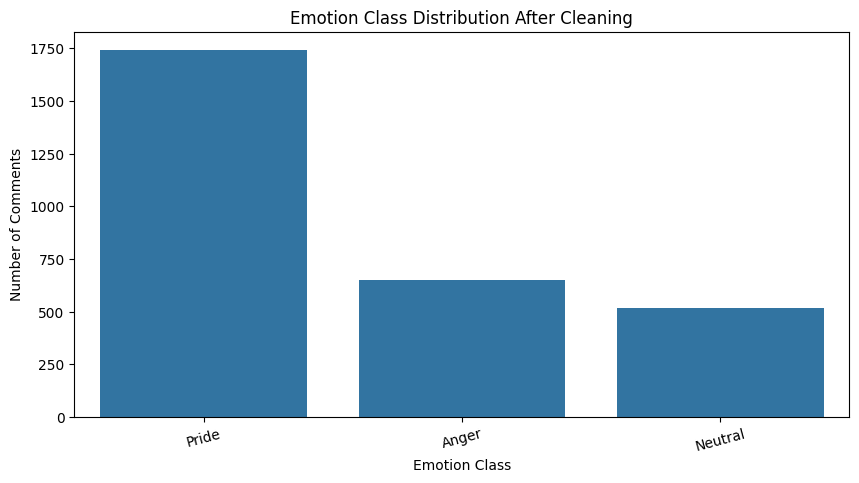

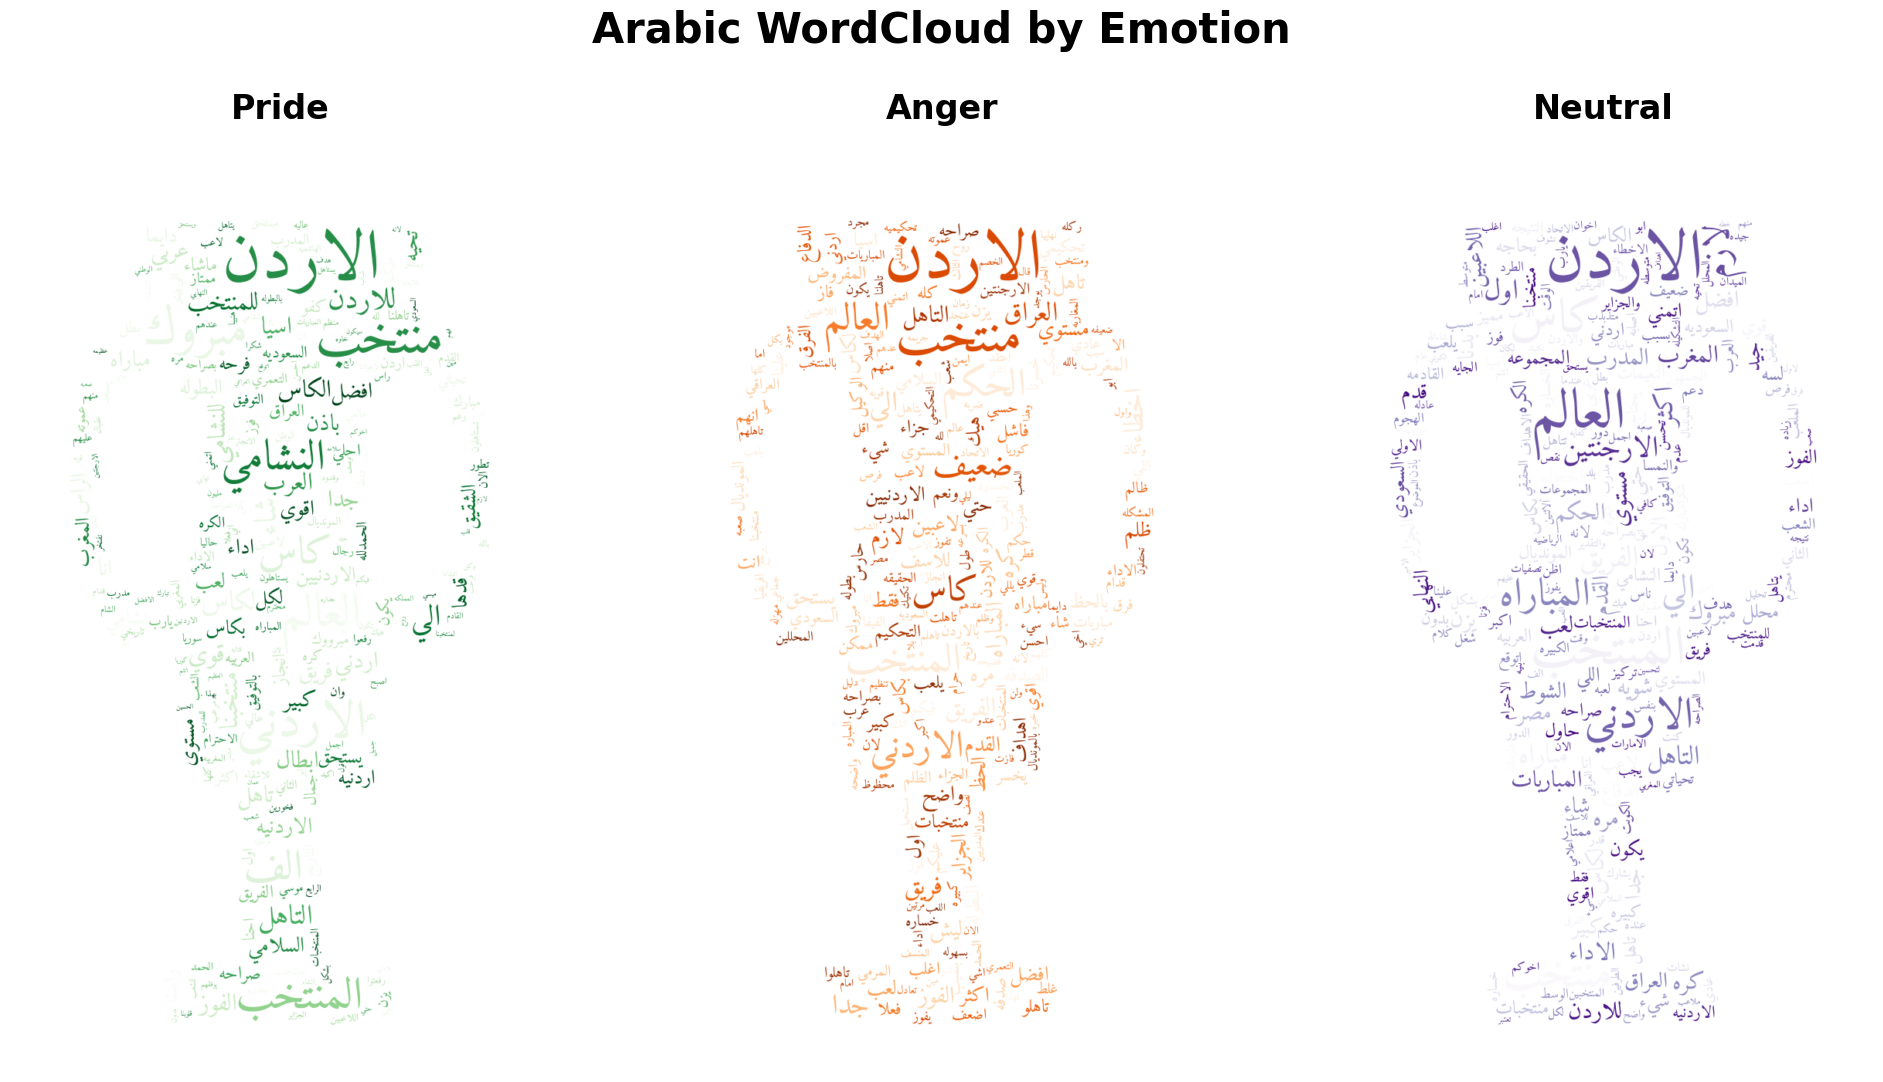


Cleaned dataset saved successfully!
Final Shape: (2911, 5)
Saved image: arabic_wordcloud_by_emotion.png


In [ ]:
!pip install arabic-reshaper python-bidi emoji nltk pyarabic wordcloud matplotlib seaborn odfpy pillow -q

import re
import emoji
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arabic_reshaper
import numpy as np

from pyarabic.araby import strip_tashkeel
from nltk.corpus import stopwords
from wordcloud import WordCloud
from PIL import Image, ImageDraw

nltk.download('stopwords')

!wget -q -O Amiri-Regular.ttf https://github.com/google/fonts/raw/main/ofl/amiri/Amiri-Regular.ttf

df = pd.read_excel('/content/Nlp_dataset.ods', engine='odf')

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

TEXT_COLUMN = 'Coments'

arabic_stopwords = set(stopwords.words('arabic'))

custom_stopwords = {
    "في", "على", "من", "الى", "إلى", "عن", "مع",
    "هذا", "هاي", "هذي", "هاذ", "انه", "انو",
    "بس", "يعني", "كمان", "كتير", "كثير",
    "كان", "كانت", "صار", "صارت",
    "اذا", "إذا",
    "الله", "والله", "علي", "اليوم"
}

arabic_stopwords.update(custom_stopwords)

def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    text = emoji.replace_emoji(text, replace='')

    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)

    text = re.sub(r'\d+', '', text)

    text = re.sub(r'[^\u0600-\u06FF\s]', ' ', text)

    text = strip_tashkeel(text)

    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "و", text)
    text = re.sub("ئ", "ي", text)
    text = re.sub("ة", "ه", text)

    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()

    words = [
        word for word in words
        if word not in arabic_stopwords and len(word) > 2
    ]

    return " ".join(words)

df['Cleaned_Comment'] = df[TEXT_COLUMN].apply(clean_text)


df['Class'] = df['Emotion'].astype(str).str.strip().str.lower()

df['Class'] = df['Class'].replace({
    'pride': 'Pride',
    'anger': 'Anger',
    'neutral': 'Neutral'
})

df = df[df['Class'].isin(['Pride', 'Anger', 'Neutral'])]
df = df[df['Cleaned_Comment'].str.strip() != ""]

before_dup = len(df)
df = df.drop_duplicates(subset=['Cleaned_Comment'])
after_dup = len(df)

print("\nDuplicates removed:", before_dup - after_dup)

print("\nBefore Cleaning:")
print(df[TEXT_COLUMN].iloc[0])

print("\nAfter Cleaning:")
print(df['Cleaned_Comment'].iloc[0])

counts = df['Class'].value_counts()

result = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': (counts / len(df) * 100).round(2)
})

print("\nClass Distribution:")
display(result)

plt.figure(figsize=(10, 5))
sns.barplot(x=counts.index, y=counts.values)
plt.title('Emotion Class Distribution After Cleaning')
plt.xlabel('Emotion Class')
plt.ylabel('Number of Comments')
plt.xticks(rotation=15)
plt.show()

def create_cup_mask(width=700, height=1200):

    mask = Image.new("L", (width, height), 255)
    draw = ImageDraw.Draw(mask)

    cup_points = [
        (int(width * 0.22), int(height * 0.08)),
        (int(width * 0.78), int(height * 0.08)),
        (int(width * 0.68), int(height * 0.70)),
        (int(width * 0.58), int(height * 0.70)),
        (int(width * 0.58), int(height * 0.88)),
        (int(width * 0.72), int(height * 0.88)),
        (int(width * 0.72), int(height * 0.95)),
        (int(width * 0.28), int(height * 0.95)),
        (int(width * 0.28), int(height * 0.88)),
        (int(width * 0.42), int(height * 0.88)),
        (int(width * 0.42), int(height * 0.70)),
        (int(width * 0.32), int(height * 0.70)),
    ]

    draw.polygon(cup_points, fill=0)

    draw.ellipse(
        [
            int(width * 0.10),
            int(height * 0.18),
            int(width * 0.36),
            int(height * 0.55)
        ],
        fill=0
    )

    draw.ellipse(
        [
            int(width * 0.64),
            int(height * 0.18),
            int(width * 0.90),
            int(height * 0.55)
        ],
        fill=0
    )

    draw.ellipse(
        [
            int(width * 0.17),
            int(height * 0.25),
            int(width * 0.34),
            int(height * 0.48)
        ],
        fill=255
    )

    draw.ellipse(
        [
            int(width * 0.66),
            int(height * 0.25),
            int(width * 0.83),
            int(height * 0.48)
        ],
        fill=255
    )

    return np.array(mask)

cup_mask = create_cup_mask()


def prepare_arabic_for_wordcloud(text):
    words = text.split()

    fixed_words = []

    for word in words:
        reshaped = arabic_reshaper.reshape(word)
        fixed_words.append(reshaped)

    return " ".join(fixed_words)

emotion_colors = {
    "Pride": "Greens",
    "Anger": "Oranges",
    "Neutral": "Purples"
}

fig, axes = plt.subplots(1, 3, figsize=(20, 11))

for ax, emotion in zip(axes, ["Pride", "Anger", "Neutral"]):

    emotion_text = " ".join(
        df[df["Class"] == emotion]["Cleaned_Comment"].astype(str)
    )

    emotion_text = prepare_arabic_for_wordcloud(emotion_text)

    wordcloud = WordCloud(
        width=700,
        height=1200,
        background_color="white",
        mode="RGBA",
        mask=cup_mask,
        contour_width=0,
        collocations=False,
        font_path="Amiri-Regular.ttf",
        colormap=emotion_colors[emotion],
        max_words=250,
        min_font_size=6,
        max_font_size=90,
        prefer_horizontal=0.75,
        random_state=42
    ).generate(emotion_text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(emotion, fontsize=24, fontweight="bold", pad=20)
    ax.axis("off")

plt.suptitle("Arabic WordCloud by Emotion", fontsize=30, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig("arabic_wordcloud_by_emotion.png", dpi=300, bbox_inches="tight")
plt.show()

df.to_csv(
    'Jordan_Cleaned_Comments.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nCleaned dataset saved successfully!")
print("Final Shape:", df.shape)
print("Saved image: arabic_wordcloud_by_emotion.png")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 5.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 10.0 MB/s eta 0:00:00
Using device: cuda
Original Class Distribution:
Class
Pride      1741
Anger       652
Neutral     518
Name: count, dtype: int64

Train Distribution After Oversampling:
Class
Neutral    1218
Anger      1218
Pride      1218
Name: count, dtype: int64

Validation Distribution:
Class
Pride      262
Anger       98
Neutral     77
Name: count, dtype: int64

Test Distribution:
Class
Pride      261
Anger       98
Neutral     78
Name: count, dtype: int64


/tmp/ipykernel_3197/685830415.py:93: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Conside

Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted,Precision Macro,Recall Macro,F1 Macro
1,0.591249,0.776550,0.679634,0.744156,0.679634,0.699960,0.636002,0.646872,0.625154
2,0.323290,0.873969,0.734554,0.744758,0.734554,0.737956,0.665693,0.686091,0.674010
3,0.295833,1.078949,0.716247,0.731252,0.716247,0.721708,0.643959,0.666468,0.653074


Validation Result:
{'run': 'run_4_lr_1e-5_bs8_ep3_len128', 'learning_rate': 1e-05, 'batch_size': 8, 'epochs': 3, 'max_length': 128, 'weight_decay': 0.02, 'val_accuracy': 0.7162471395881007, 'val_f1_macro': 0.653073555221679, 'val_f1_weighted': 0.7217084632019228}

HYPERPARAMETER RESULTS


,run,learning_rate,batch_size,epochs,max_length,weight_decay,val_accuracy,val_f1_macro,val_f1_weighted
1,run_2_lr_2e-5_bs16_ep3_len96,0.00002,16,3,96,0.02,0.739130,0.675872,0.742587
0,run_1_lr_1e-5_bs16_ep3_len96,0.00001,16,3,96,0.02,0.736842,0.667642,0.740998
2,run_3_lr_1e-5_bs16_ep4_len96,0.00001,16,4,96,0.02,0.729977,0.664593,0.735009
3,run_4_lr_1e-5_bs8_ep3_len128,0.00001,8,3,128,0.02,0.716247,0.653074,0.721708



Best Config:
{'name': 'run_2_lr_2e-5_bs16_ep3_len96', 'learning_rate': 2e-05, 'batch_size': 16, 'epochs': 3, 'max_length': 96, 'weight_decay': 0.02}

FINAL TEST RESULTS - BEST MODEL
              precision    recall  f1-score   support

       Anger       0.65      0.69      0.67        98
     Neutral       0.52      0.51      0.52        78
       Pride       0.87      0.85      0.86       261

    accuracy                           0.76       437
   macro avg       0.68      0.69      0.68       437
weighted avg       0.76      0.76      0.76       437



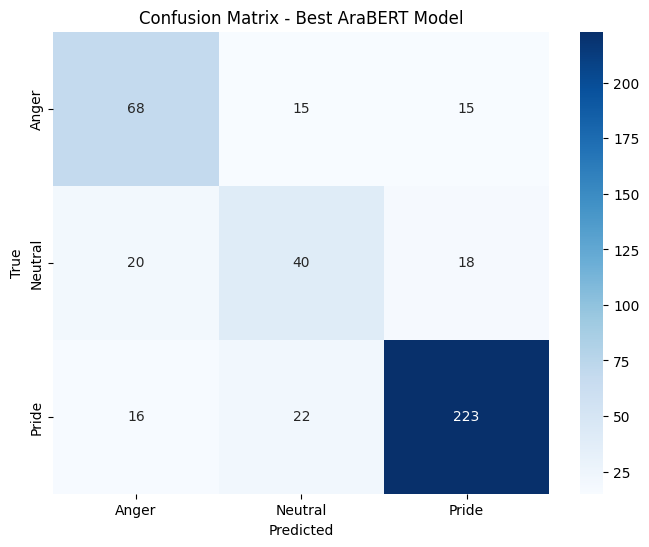

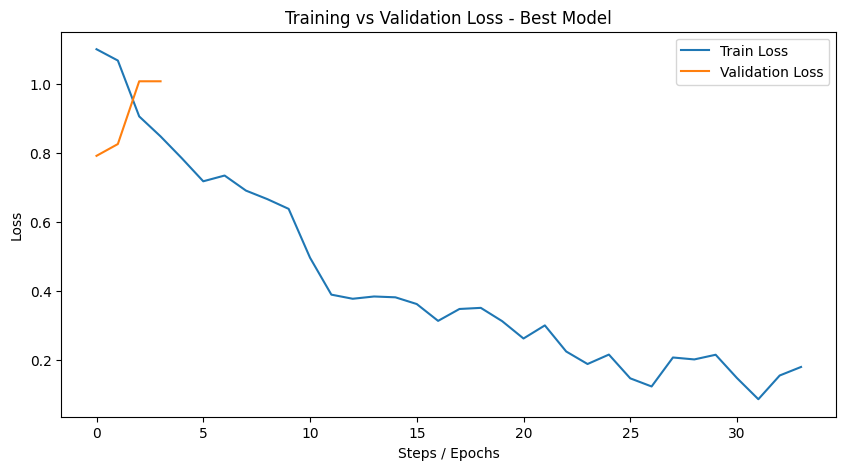

In [ ]:
!pip install transformers datasets evaluate scikit-learn arabert accelerate -q

import random
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

set_seed(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

df = pd.read_csv("Jordan_Cleaned_Comments.csv")

df = df[["Cleaned_Comment", "Class"]].dropna()


df = df[df["Cleaned_Comment"].str.strip() != ""]



labels = sorted(df["Class"].unique())

label2id = {
    label: i
    for i, label in enumerate(labels)
}

id2label = {
    i: label
    for label, i in label2id.items()
}

df["label"] = df["Class"].map(label2id)

print("Original Class Distribution:")
print(df["Class"].value_counts())



train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)



max_count = train_df["Class"].value_counts().max()

train_df_balanced = (
    train_df
    .groupby("Class", group_keys=False)
    .apply(
        lambda x: x.sample(
            max_count,
            replace=True,
            random_state=SEED
        )
    )
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

print("\nTrain Distribution After Oversampling:")
print(train_df_balanced["Class"].value_counts())

print("\nValidation Distribution:")
print(val_df["Class"].value_counts())

print("\nTest Distribution:")
print(test_df["Class"].value_counts())


model_name = "aubmindlab/bert-base-arabertv02"

tokenizer = AutoTokenizer.from_pretrained(model_name)



class NLPDataset(torch.utils.data.Dataset):

    def __init__(self, texts, labels, tokenizer, max_length):

        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            padding=True,
            max_length=max_length
        )

        self.labels = np.array(labels)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(value[idx])
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

    def __len__(self):

        return len(self.labels)



def compute_metrics(pred):

    predictions = np.argmax(
        pred.predictions,
        axis=1
    )

    true_labels = pred.label_ids

    precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    precision_m, recall_m, f1_m, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    acc = accuracy_score(
        true_labels,
        predictions
    )

    return {
        "accuracy": acc,
        "precision_weighted": precision_w,
        "recall_weighted": recall_w,
        "f1_weighted": f1_w,
        "precision_macro": precision_m,
        "recall_macro": recall_m,
        "f1_macro": f1_m
    }



experiments = [
    {
        "name": "run_1_lr_1e-5_bs16_ep3_len96",
        "learning_rate": 1e-5,
        "batch_size": 16,
        "epochs": 3,
        "max_length": 96,
        "weight_decay": 0.02
    },

    {
        "name": "run_2_lr_2e-5_bs16_ep3_len96",
        "learning_rate": 2e-5,
        "batch_size": 16,
        "epochs": 3,
        "max_length": 96,
        "weight_decay": 0.02
    },

    {
        "name": "run_3_lr_1e-5_bs16_ep4_len96",
        "learning_rate": 1e-5,
        "batch_size": 16,
        "epochs": 4,
        "max_length": 96,
        "weight_decay": 0.02
    },

    {
        "name": "run_4_lr_1e-5_bs8_ep3_len128",
        "learning_rate": 1e-5,
        "batch_size": 8,
        "epochs": 3,
        "max_length": 128,
        "weight_decay": 0.02
    }
]


results = []

best_trainer = None
best_config = None
best_val_f1 = -1

for exp in experiments:

    print("\n==============================")
    print("Running:", exp["name"])
    print("==============================")

    set_seed(SEED)

    train_dataset = NLPDataset(
        train_df_balanced["Cleaned_Comment"],
        train_df_balanced["label"].values,
        tokenizer,
        exp["max_length"]
    )

    val_dataset = NLPDataset(
        val_df["Cleaned_Comment"],
        val_df["label"].values,
        tokenizer,
        exp["max_length"]
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(labels),
        id2label=id2label,
        label2id=label2id
    ).to(device)

    training_args = TrainingArguments(

        output_dir=f"./results_{exp['name']}",

        eval_strategy="epoch",
        save_strategy="no",

        learning_rate=exp["learning_rate"],

        per_device_train_batch_size=exp["batch_size"],
        per_device_eval_batch_size=exp["batch_size"],

        num_train_epochs=exp["epochs"],

        weight_decay=exp["weight_decay"],

        warmup_ratio=0.05,

        logging_steps=20,

        fp16=torch.cuda.is_available(),

        report_to="none",

        seed=SEED,
        data_seed=SEED
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()

    val_result = trainer.evaluate(val_dataset)

    row = {
        "run": exp["name"],
        "learning_rate": exp["learning_rate"],
        "batch_size": exp["batch_size"],
        "epochs": exp["epochs"],
        "max_length": exp["max_length"],
        "weight_decay": exp["weight_decay"],
        "val_accuracy": val_result["eval_accuracy"],
        "val_f1_macro": val_result["eval_f1_macro"],
        "val_f1_weighted": val_result["eval_f1_weighted"]
    }

    results.append(row)

    print("Validation Result:")
    print(row)


    if val_result["eval_f1_macro"] > best_val_f1:

        best_val_f1 = val_result["eval_f1_macro"]

        best_trainer = trainer
        best_config = exp



results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="val_f1_macro",
    ascending=False
)

print("\n==============================")
print("HYPERPARAMETER RESULTS")
print("==============================")

display(results_df)

print("\nBest Config:")
print(best_config)



test_dataset = NLPDataset(
    test_df["Cleaned_Comment"],
    test_df["label"].values,
    tokenizer,
    best_config["max_length"]
)

test_preds = best_trainer.predict(test_dataset)

y_test_pred = np.argmax(
    test_preds.predictions,
    axis=1
)

y_test_true = test_df["label"].to_numpy()

print("\n==============================")
print("FINAL TEST RESULTS - BEST MODEL")
print("==============================")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=labels,
        zero_division=0
    )
)


cm = confusion_matrix(
    y_test_true,
    y_test_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Best AraBERT Model")

plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()



log_history = best_trainer.state.log_history

train_loss = [
    x["loss"]
    for x in log_history
    if "loss" in x
]

eval_loss = [
    x["eval_loss"]
    for x in log_history
    if "eval_loss" in x
]

plt.figure(figsize=(10, 5))

plt.plot(train_loss, label="Train Loss")
plt.plot(eval_loss, label="Validation Loss")

plt.title("Training vs Validation Loss - Best Model")

plt.xlabel("Steps / Epochs")
plt.ylabel("Loss")

plt.legend()

plt.show()

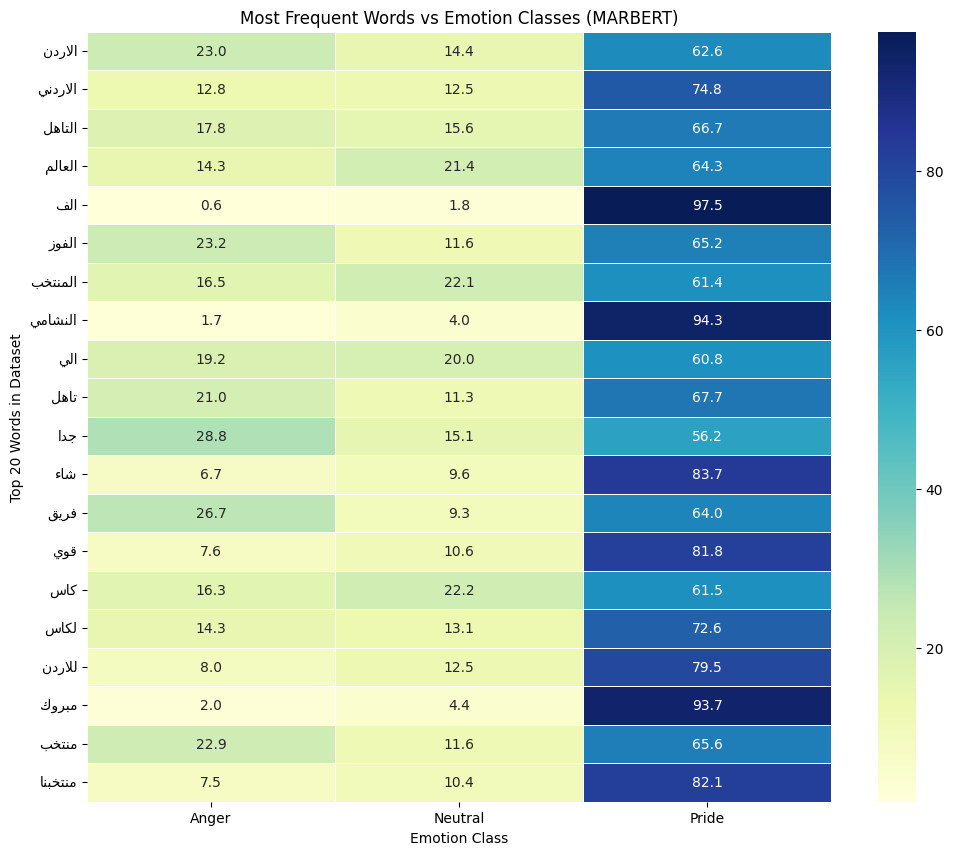

In [ ]:
import arabic_reshaper
from bidi.algorithm import get_display

df_exploded = df.assign(
    Words=df['Cleaned_Comment'].str.split()
).explode('Words')


top_words = (
    df_exploded['Words']
    .value_counts()
    .head(20)
    .index
)

df_top_words = df_exploded[
    df_exploded['Words'].isin(top_words)
]


heatmap_data = pd.crosstab(
    df_top_words['Words'],
    df_top_words['Class']
)

heatmap_percent = (
    heatmap_data.div(
        heatmap_data.sum(axis=1),
        axis=0
    ) * 100
)


reshaped_words = [
    get_display(arabic_reshaper.reshape(str(word)))
    for word in heatmap_percent.index
]


plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    yticklabels=reshaped_words
)

plt.title("Most Frequent Words vs Emotion Classes (MARBERT)")
plt.xlabel("Emotion Class")
plt.ylabel("Top 20 Words in Dataset")

plt.show()

Using device: cuda
Emotion Distribution:
Class
Pride      1741
Anger       652
Neutral     518
Name: count, dtype: int64

Train Distribution:
Class
Neutral    1218
Anger      1218
Pride      1218
Name: count, dtype: int64

Validation Distribution:
Class
Pride      262
Anger       98
Neutral     77
Name: count, dtype: int64

Test Distribution:
Class
Pride      261
Anger       98
Neutral     78
Name: count, dtype: int64


/tmp/ipykernel_3197/375337595.py:83: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(max_count, replace=True, random_state=SEED))


config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on yo

Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted,Precision Macro,Recall Macro,F1 Macro
1,0.431139,0.741666,0.743707,0.753332,0.743707,0.747932,0.670467,0.679333,0.674047
2,0.247067,1.229827,0.755149,0.759928,0.755149,0.755976,0.676891,0.691701,0.682244
3,0.209758,1.353605,0.766590,0.769818,0.766590,0.767477,0.695595,0.706031,0.699864


Validation Result: {'run': 'run_4_lr_1e-5_bs8_ep3_len128', 'learning_rate': 1e-05, 'batch_size': 8, 'epochs': 3, 'max_length': 128, 'weight_decay': 0.02, 'val_accuracy': 0.7665903890160183, 'val_f1_macro': 0.6998640710754129, 'val_f1_weighted': 0.7674773618760968}

HYPERPARAMETER RESULTS - MARBERT


,run,learning_rate,batch_size,epochs,max_length,weight_decay,val_accuracy,val_f1_macro,val_f1_weighted
1,run_2_lr_2e-5_bs16_ep3_len96,0.00002,16,3,96,0.02,0.778032,0.717461,0.779222
0,run_1_lr_1e-5_bs16_ep3_len96,0.00001,16,3,96,0.02,0.768879,0.701143,0.769962
3,run_4_lr_1e-5_bs8_ep3_len128,0.00001,8,3,128,0.02,0.766590,0.699864,0.767477
2,run_3_lr_1e-5_bs16_ep4_len96,0.00001,16,4,96,0.02,0.762014,0.699248,0.766525



Best Config:
{'name': 'run_2_lr_2e-5_bs16_ep3_len96', 'learning_rate': 2e-05, 'batch_size': 16, 'epochs': 3, 'max_length': 96, 'weight_decay': 0.02}

FINAL TEST RESULTS - BEST MARBERT MODEL
              precision    recall  f1-score   support

       Anger       0.65      0.67      0.66        98
     Neutral       0.55      0.51      0.53        78
       Pride       0.87      0.88      0.88       261

    accuracy                           0.77       437
   macro avg       0.69      0.69      0.69       437
weighted avg       0.76      0.77      0.77       437



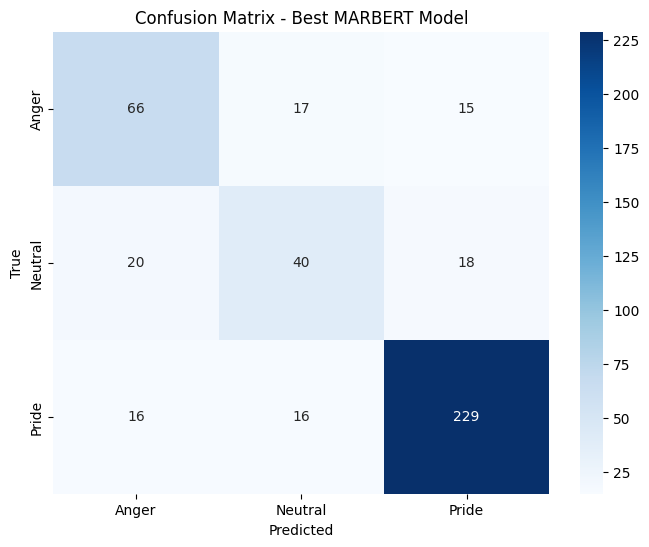

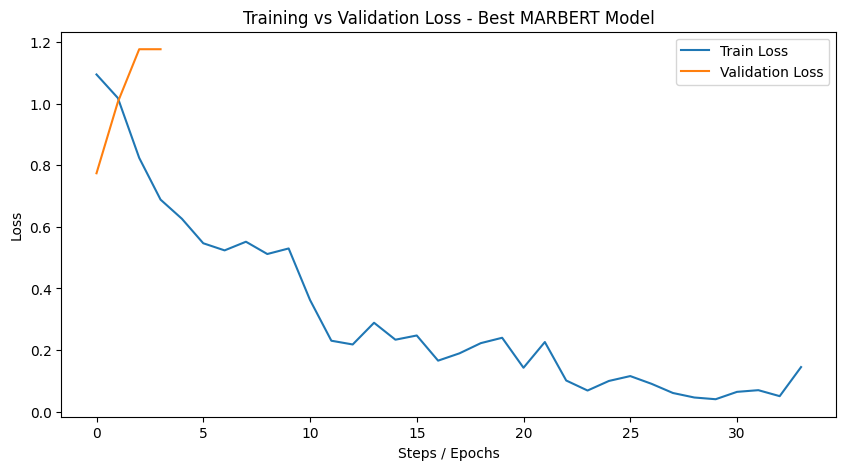

In [ ]:
!pip install transformers datasets evaluate scikit-learn accelerate -q

import random
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)


SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

set_seed(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)



df = pd.read_csv("Jordan_Cleaned_Comments.csv")
df = df[["Cleaned_Comment", "Class"]].dropna()
df = df[df["Cleaned_Comment"].str.strip() != ""]


labels = sorted(df["Class"].unique())
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["Class"].map(label2id)

print("Emotion Distribution:")
print(df["Class"].value_counts())



train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)



max_count = train_df["Class"].value_counts().max()

train_df_balanced = (
    train_df
    .groupby("Class", group_keys=False)
    .apply(lambda x: x.sample(max_count, replace=True, random_state=SEED))
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

print("\nTrain Distribution:")
print(train_df_balanced["Class"].value_counts())

print("\nValidation Distribution:")
print(val_df["Class"].value_counts())

print("\nTest Distribution:")
print(test_df["Class"].value_counts())


model_name = "UBC-NLP/MARBERT"
tokenizer = AutoTokenizer.from_pretrained(model_name)



class NLPDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            padding=True,
            max_length=max_length
        )
        self.labels = np.array(labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(value[idx])
            for key, value in self.encodings.items()
        }
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


def compute_metrics(pred):
    predictions = np.argmax(pred.predictions, axis=1)
    true_labels = pred.label_ids

    precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
        true_labels, predictions, average="weighted", zero_division=0
    )

    precision_m, recall_m, f1_m, _ = precision_recall_fscore_support(
        true_labels, predictions, average="macro", zero_division=0
    )

    acc = accuracy_score(true_labels, predictions)

    return {
        "accuracy": acc,
        "precision_weighted": precision_w,
        "recall_weighted": recall_w,
        "f1_weighted": f1_w,
        "precision_macro": precision_m,
        "recall_macro": recall_m,
        "f1_macro": f1_m
    }


experiments = [
    {"name": "run_1_lr_1e-5_bs16_ep3_len96", "learning_rate": 1e-5, "batch_size": 16, "epochs": 3, "max_length": 96, "weight_decay": 0.02},
    {"name": "run_2_lr_2e-5_bs16_ep3_len96", "learning_rate": 2e-5, "batch_size": 16, "epochs": 3, "max_length": 96, "weight_decay": 0.02},
    {"name": "run_3_lr_1e-5_bs16_ep4_len96", "learning_rate": 1e-5, "batch_size": 16, "epochs": 4, "max_length": 96, "weight_decay": 0.02},
    {"name": "run_4_lr_1e-5_bs8_ep3_len128", "learning_rate": 1e-5, "batch_size": 8, "epochs": 3, "max_length": 128, "weight_decay": 0.02}
]



results = []
best_trainer = None
best_config = None
best_val_f1 = -1

for exp in experiments:

    print("\n==============================")
    print("Running:", exp["name"])
    print("==============================")

    set_seed(SEED)

    train_dataset = NLPDataset(
        train_df_balanced["Cleaned_Comment"],
        train_df_balanced["label"].values,
        tokenizer,
        exp["max_length"]
    )

    val_dataset = NLPDataset(
        val_df["Cleaned_Comment"],
        val_df["label"].values,
        tokenizer,
        exp["max_length"]
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(labels),
        id2label=id2label,
        label2id=label2id
    ).to(device)

    training_args = TrainingArguments(
        output_dir=f"./results_{exp['name']}",
        eval_strategy="epoch",
        save_strategy="no",
        learning_rate=exp["learning_rate"],
        per_device_train_batch_size=exp["batch_size"],
        per_device_eval_batch_size=exp["batch_size"],
        num_train_epochs=exp["epochs"],
        weight_decay=exp["weight_decay"],
        warmup_ratio=0.05,
        logging_steps=20,
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED,
        data_seed=SEED
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()

    val_result = trainer.evaluate(val_dataset)

    row = {
        "run": exp["name"],
        "learning_rate": exp["learning_rate"],
        "batch_size": exp["batch_size"],
        "epochs": exp["epochs"],
        "max_length": exp["max_length"],
        "weight_decay": exp["weight_decay"],
        "val_accuracy": val_result["eval_accuracy"],
        "val_f1_macro": val_result["eval_f1_macro"],
        "val_f1_weighted": val_result["eval_f1_weighted"]
    }

    results.append(row)

    print("Validation Result:", row)

    if val_result["eval_f1_macro"] > best_val_f1:
        best_val_f1 = val_result["eval_f1_macro"]
        best_trainer = trainer
        best_config = exp



results_df = pd.DataFrame(results).sort_values(by="val_f1_macro", ascending=False)

print("\n==============================")
print("HYPERPARAMETER RESULTS - MARBERT")
print("==============================")

display(results_df)

print("\nBest Config:")
print(best_config)



test_dataset = NLPDataset(
    test_df["Cleaned_Comment"],
    test_df["label"].values,
    tokenizer,
    best_config["max_length"]
)

test_preds = best_trainer.predict(test_dataset)

y_test_pred = np.argmax(test_preds.predictions, axis=1)
y_test_true = test_df["label"].to_numpy()

print("\n==============================")
print("FINAL TEST RESULTS - BEST MARBERT MODEL")
print("==============================")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=labels,
        zero_division=0
    )
)



cm = confusion_matrix(y_test_true, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)

plt.title("Confusion Matrix - Best MARBERT Model")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


log_history = best_trainer.state.log_history

train_loss = [x["loss"] for x in log_history if "loss" in x]
eval_loss = [x["eval_loss"] for x in log_history if "eval_loss" in x]

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label="Train Loss")
plt.plot(eval_loss, label="Validation Loss")
plt.title("Training vs Validation Loss - Best MARBERT Model")
plt.xlabel("Steps / Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

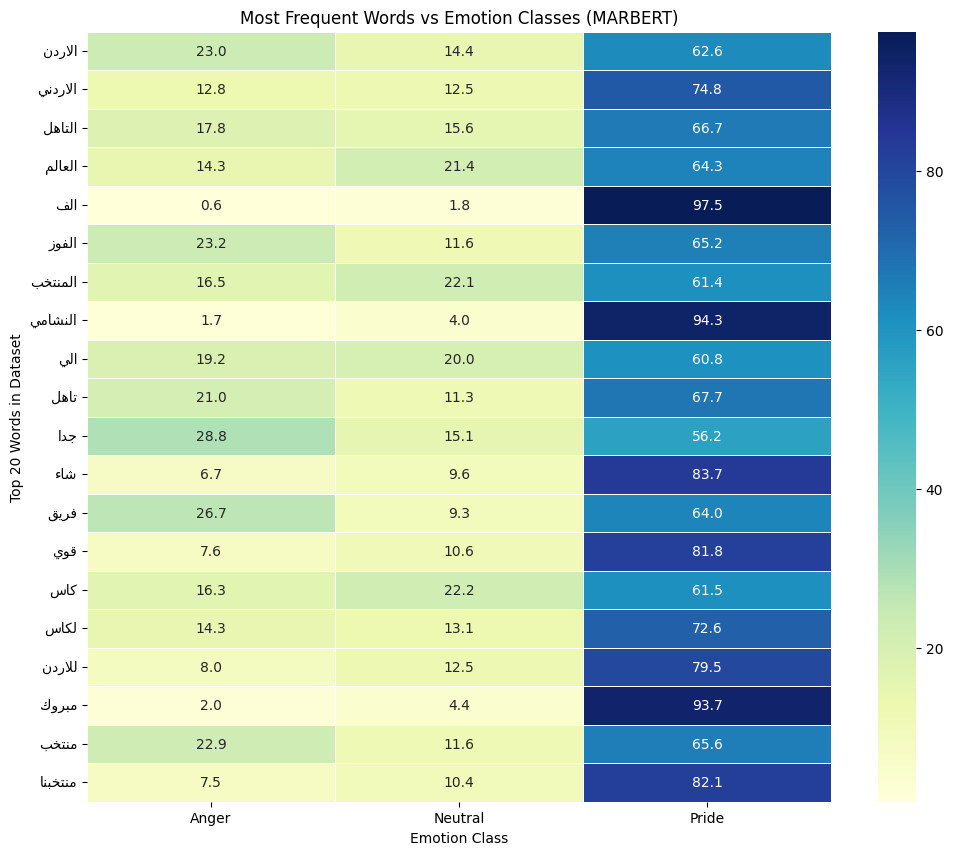

In [ ]:
import arabic_reshaper
from bidi.algorithm import get_display


df_exploded = df.assign(
    Words=df['Cleaned_Comment'].str.split()
).explode('Words')


top_words = (
    df_exploded['Words']
    .value_counts()
    .head(20)
    .index
)


df_top_words = df_exploded[
    df_exploded['Words'].isin(top_words)
]


heatmap_data = pd.crosstab(
    df_top_words['Words'],
    df_top_words['Class']
)


heatmap_percent = (
    heatmap_data.div(
        heatmap_data.sum(axis=1),
        axis=0
    ) * 100
)


reshaped_words = [
    get_display(arabic_reshaper.reshape(str(word)))
    for word in heatmap_percent.index
]


plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    yticklabels=reshaped_words
)

plt.title("Most Frequent Words vs Emotion Classes (MARBERT)")
plt.xlabel("Emotion Class")
plt.ylabel("Top 20 Words in Dataset")

plt.show()

Using device: cuda
Original Emotion Distribution:
Class
Pride      1741
Anger       652
Neutral     518
Name: count, dtype: int64

Train Distribution After Oversampling:
Class
Neutral    1218
Anger      1218
Pride      1218
Name: count, dtype: int64

Validation Distribution:
Class
Pride      262
Anger       98
Neutral     77
Name: count, dtype: int64

Test Distribution:
Class
Pride      261
Anger       98
Neutral     78
Name: count, dtype: int64


/tmp/ipykernel_3197/2613506978.py:78: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(max_count, replace=True, random_state=SEED))


config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

BertForSequenceClassification LOAD REPORT from: asafaya/bert-base-arabic
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted,Precision Macro,Recall Macro,F1 Macro
1,0.549627,0.828139,0.656751,0.735040,0.656751,0.679511,0.621717,0.646924,0.615424
2,0.264049,1.146464,0.688787,0.714344,0.688787,0.698498,0.626968,0.643339,0.630948
3,0.143715,1.510063,0.691076,0.714815,0.691076,0.700303,0.621221,0.641828,0.628484


Validation Result: {'run': 'arabicbert_run_4_lr_1e-5_bs8_ep3_len128', 'learning_rate': 1e-05, 'batch_size': 8, 'epochs': 3, 'max_length': 128, 'weight_decay': 0.02, 'val_accuracy': 0.6910755148741419, 'val_f1_macro': 0.628483544947848, 'val_f1_weighted': 0.700302977813222}

HYPERPARAMETER RESULTS - ARABIC BERT


,run,learning_rate,batch_size,epochs,max_length,weight_decay,val_accuracy,val_f1_macro,val_f1_weighted
3,arabicbert_run_4_lr_1e-5_bs8_ep3_len128,0.00001,8,3,128,0.02,0.691076,0.628484,0.700303
2,arabicbert_run_3_lr_1e-5_bs16_ep4_len96,0.00001,16,4,96,0.02,0.688787,0.622759,0.697660
1,arabicbert_run_2_lr_2e-5_bs16_ep3_len96,0.00002,16,3,96,0.02,0.681922,0.616747,0.694145
0,arabicbert_run_1_lr_1e-5_bs16_ep3_len96,0.00001,16,3,96,0.02,0.679634,0.614914,0.689419



Best Config:
{'name': 'arabicbert_run_4_lr_1e-5_bs8_ep3_len128', 'learning_rate': 1e-05, 'batch_size': 8, 'epochs': 3, 'max_length': 128, 'weight_decay': 0.02}

FINAL TEST RESULTS - BEST MODEL
              precision    recall  f1-score   support

       Anger       0.61      0.63      0.62        98
     Neutral       0.43      0.47      0.45        78
       Pride       0.86      0.82      0.84       261

    accuracy                           0.72       437
   macro avg       0.63      0.64      0.64       437
weighted avg       0.73      0.72      0.72       437



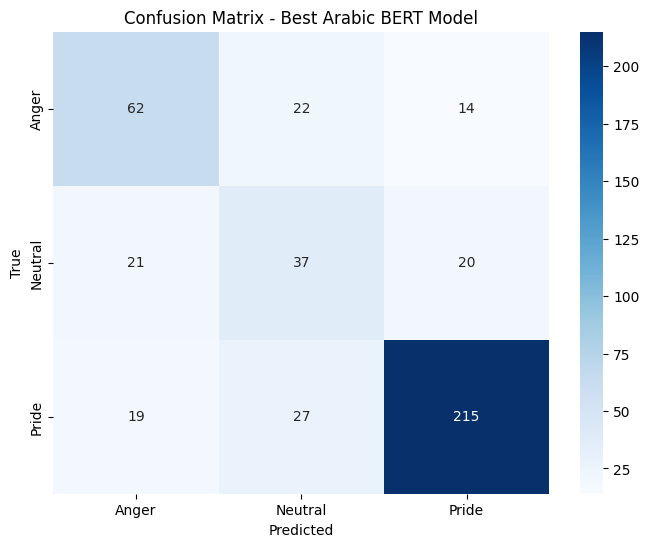

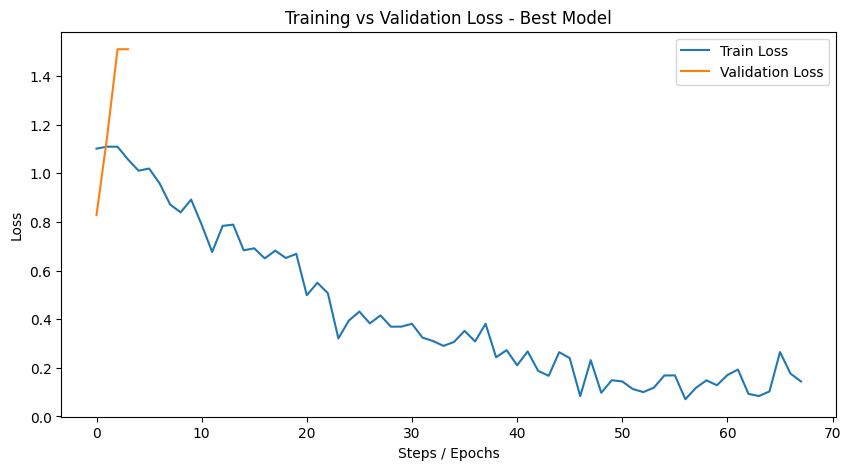

In [ ]:
!pip install transformers datasets evaluate scikit-learn accelerate -q

import random
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


df = pd.read_csv("Jordan_Cleaned_Comments.csv")

df = df[["Cleaned_Comment", "Class"]].dropna()

df = df[df["Cleaned_Comment"].str.strip() != ""]


labels = sorted(df["Class"].unique())
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["Class"].map(label2id)

print("Original Emotion Distribution:")
print(df["Class"].value_counts())

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)


max_count = train_df["Class"].value_counts().max()

train_df_balanced = (
    train_df
    .groupby("Class", group_keys=False)
    .apply(lambda x: x.sample(max_count, replace=True, random_state=SEED))
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

print("\nTrain Distribution After Oversampling:")
print(train_df_balanced["Class"].value_counts())

print("\nValidation Distribution:")
print(val_df["Class"].value_counts())

print("\nTest Distribution:")
print(test_df["Class"].value_counts())


model_name = "asafaya/bert-base-arabic"
tokenizer = AutoTokenizer.from_pretrained(model_name)


class NLPDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            padding=True,
            max_length=max_length
        )
        self.labels = np.array(labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(value[idx])
            for key, value in self.encodings.items()
        }
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


def compute_metrics(pred):
    predictions = np.argmax(pred.predictions, axis=1)
    true_labels = pred.label_ids

    precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    precision_m, recall_m, f1_m, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    acc = accuracy_score(true_labels, predictions)

    return {
        "accuracy": acc,
        "precision_weighted": precision_w,
        "recall_weighted": recall_w,
        "f1_weighted": f1_w,
        "precision_macro": precision_m,
        "recall_macro": recall_m,
        "f1_macro": f1_m
    }


experiments = [
    {
        "name": "arabicbert_run_1_lr_1e-5_bs16_ep3_len96",
        "learning_rate": 1e-5,
        "batch_size": 16,
        "epochs": 3,
        "max_length": 96,
        "weight_decay": 0.02
    },
    {
        "name": "arabicbert_run_2_lr_2e-5_bs16_ep3_len96",
        "learning_rate": 2e-5,
        "batch_size": 16,
        "epochs": 3,
        "max_length": 96,
        "weight_decay": 0.02
    },
    {
        "name": "arabicbert_run_3_lr_1e-5_bs16_ep4_len96",
        "learning_rate": 1e-5,
        "batch_size": 16,
        "epochs": 4,
        "max_length": 96,
        "weight_decay": 0.02
    },
    {
        "name": "arabicbert_run_4_lr_1e-5_bs8_ep3_len128",
        "learning_rate": 1e-5,
        "batch_size": 8,
        "epochs": 3,
        "max_length": 128,
        "weight_decay": 0.02
    }
]


results = []
best_trainer = None
best_config = None
best_val_f1 = -1


for exp in experiments:

    print("\n==============================")
    print("Running:", exp["name"])
    print("==============================")

    set_seed(SEED)

    train_dataset = NLPDataset(
        train_df_balanced["Cleaned_Comment"],
        train_df_balanced["label"].values,
        tokenizer,
        exp["max_length"]
    )

    val_dataset = NLPDataset(
        val_df["Cleaned_Comment"],
        val_df["label"].values,
        tokenizer,
        exp["max_length"]
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(labels),
        id2label=id2label,
        label2id=label2id
    ).to(device)

    training_args = TrainingArguments(
        output_dir=f"./results_{exp['name']}",

        eval_strategy="epoch",
        save_strategy="no",

        learning_rate=exp["learning_rate"],
        per_device_train_batch_size=exp["batch_size"],
        per_device_eval_batch_size=exp["batch_size"],

        num_train_epochs=exp["epochs"],
        weight_decay=exp["weight_decay"],
        warmup_ratio=0.05,

        logging_steps=20,

        fp16=torch.cuda.is_available(),
        report_to="none",

        seed=SEED,
        data_seed=SEED
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()

    val_result = trainer.evaluate(val_dataset)

    row = {
        "run": exp["name"],
        "learning_rate": exp["learning_rate"],
        "batch_size": exp["batch_size"],
        "epochs": exp["epochs"],
        "max_length": exp["max_length"],
        "weight_decay": exp["weight_decay"],
        "val_accuracy": val_result["eval_accuracy"],
        "val_f1_macro": val_result["eval_f1_macro"],
        "val_f1_weighted": val_result["eval_f1_weighted"]
    }

    results.append(row)

    print("Validation Result:", row)

    if val_result["eval_f1_macro"] > best_val_f1:
        best_val_f1 = val_result["eval_f1_macro"]
        best_trainer = trainer
        best_config = exp


results_df = pd.DataFrame(results).sort_values(
    by="val_f1_macro",
    ascending=False
)

print("\n==============================")
print("HYPERPARAMETER RESULTS - ARABIC BERT")
print("==============================")
display(results_df)

print("\nBest Config:")
print(best_config)


test_dataset = NLPDataset(
    test_df["Cleaned_Comment"],
    test_df["label"].values,
    tokenizer,
    best_config["max_length"]
)

test_preds = best_trainer.predict(test_dataset)

y_test_pred = np.argmax(test_preds.predictions, axis=1)
y_test_true = test_df["label"].to_numpy()

print("\n==============================")
print("FINAL TEST RESULTS - BEST MODEL")
print("==============================")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=labels,
        zero_division=0
    )
)

cm = confusion_matrix(y_test_true, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Best Arabic BERT Model")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


log_history = best_trainer.state.log_history

train_loss = [x["loss"] for x in log_history if "loss" in x]
eval_loss = [x["eval_loss"] for x in log_history if "eval_loss" in x]

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label="Train Loss")
plt.plot(eval_loss, label="Validation Loss")
plt.title("Training vs Validation Loss - Best Model")
plt.xlabel("Steps / Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

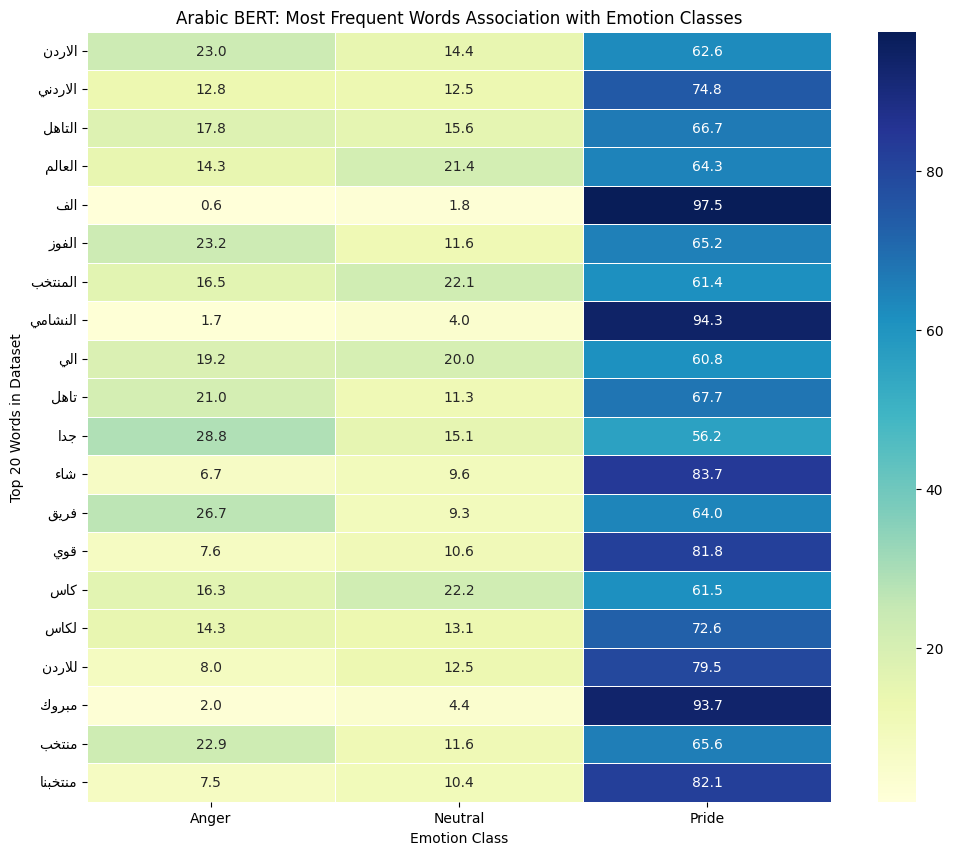

In [ ]:
df_exploded = df.assign(
    Words=df['Cleaned_Comment'].str.split()
).explode('Words')

top_words = (
    df_exploded['Words']
    .value_counts()
    .head(20)
    .index
)

df_top_words = df_exploded[
    df_exploded['Words'].isin(top_words)
]

heatmap_data = pd.crosstab(
    df_top_words['Words'],
    df_top_words['Class']
)

heatmap_percent = (
    heatmap_data.divide(
        heatmap_data.sum(axis=1),
        axis=0
    ) * 100
)


reshaped_words = [
    get_display(
        arabic_reshaper.reshape(str(word))
    )
    for word in heatmap_percent.index
]

plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    yticklabels=reshaped_words
)

plt.title(
    "Arabic BERT: Most Frequent Words Association with Emotion Classes"
)

plt.xlabel("Emotion Class")
plt.ylabel("Top 20 Words in Dataset")

plt.show()


SMART TF-IDF KEYWORDS

Pride --> ['النشامي', 'مبروك', 'الف', 'الف مبروك', 'شاء', 'قوي', 'للاردن', 'منتخبنا', 'الي', 'لكاس', 'التاهل', 'للمنتخب', 'للنشامي', 'ابطال', 'الكاس']
Neutral --> ['الارجنتين', 'الي', 'اكثر', 'اول', 'بدنا', 'الاداء', 'الحكم', 'التاهل', 'بحاجه', 'جيد', 'مستوي', 'شويه', 'مره', 'اللي', 'محلل']
Anger --> ['الحكم', 'ضعيف', 'فريق', 'اخطاء', 'العراق', 'ليش', 'الي', 'التاهل', 'ظلم', 'الفوز', 'الصدفه', 'للاسف', 'بالحظ', 'الحظ', 'الدفاع']

اكتب تعليق عربي ,أو اكتب خروج لإنهاء البرنامج: السبب هو كان دفاع بطيء جدا بشكل غريب لياقه ماكو سرعه ماكو مهاجمين يدخلون ينفرضون بسهوله تقولوا المنتخب كان مسيطر لان ماكو هجمات خضراء علي الاردن الشوط الاول الاول اذا لاحظتوا ايضا اكو شغله عندنا لاعبين مثل ابراهيم بايش وعلي جاسم واحمد يحك اريتفلسفون كلش هوايه يحاولون يسوون معجزات علي اليسار

TEXT: السبب هو كان دفاع بطيء جدا بشكل غريب لياقه ماكو سرعه ماكو مهاجمين يدخلون ينفرضون بسهوله تقولوا المنتخب كان مسيطر لان ماكو هجمات خضراء علي الاردن الشوط الاول الاول اذا لاحظتوا ايضا اكو شغله عندنا ل

,token,shap_value
28,مسي,0.020271
20,رض,0.018823
31,ماكو,0.015381
18,يدخلون,0.013819
29,طر,0.011012
30,لان,0.009713
6,ء,0.009661
59,فلس,0.009110
71,اليسار,0.008998
70,علي,0.008998


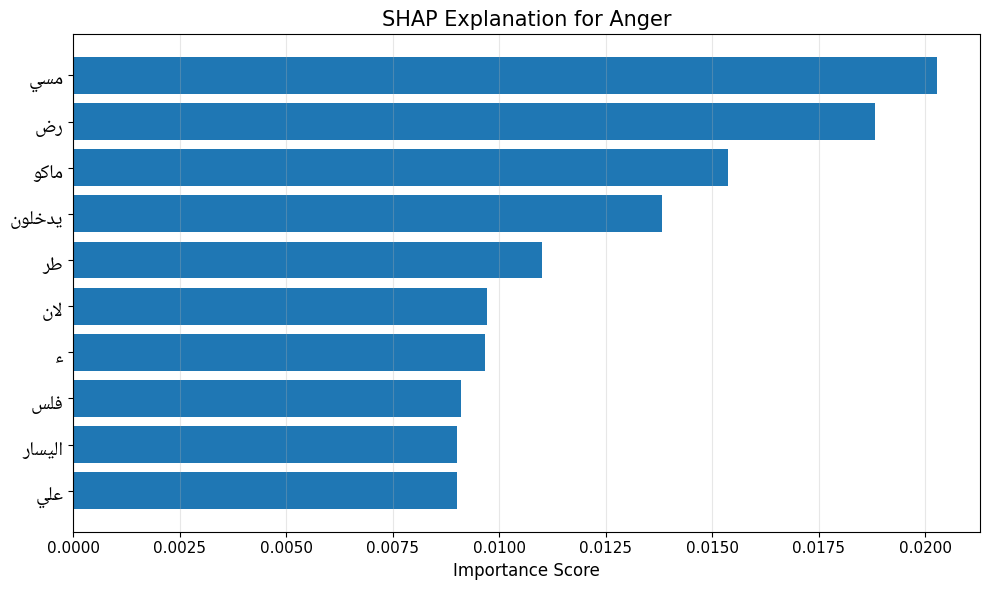


اكتب تعليق عربي ,أو اكتب خروج لإنهاء البرنامج: فرحه العيد فرحتين للمنتخب الاردني الترشح لنهائيات كأس العالم لاول مره في التاريخ فرحه كبيره وكبيره جدا في الصفوف الاردنيه في الجماهير الاردنيه مبروك نقوللكم من هنا تونس ونبارك لاشقائنا العرب

TEXT: فرحه العيد فرحتين للمنتخب الاردني الترشح لنهائيات كأس العالم لاول مره في التاريخ فرحه كبيره وكبيره جدا في الصفوف الاردنيه في الجماهير الاردنيه مبروك نقوللكم من هنا تونس ونبارك لاشقائنا العرب
CLEANED: فرحه العيد فرحتين للمنتخب الاردني الترشح لنهاييات كاس العالم لاول مره في التاريخ فرحه كبيره وكبيره جدا في الصفوف الاردنيه في الجماهير الاردنيه مبروك نقوللكم من هنا تونس ونبارك لاشقاينا العرب
PREDICTION: Pride
CONFIDENCE: 98.82 %
KEYWORDS: ['مبروك', 'للمنتخب']

SHAP EXPLANATION
TEXT: فرحه العيد فرحتين للمنتخب الاردني الترشح لنهائيات كأس العالم لاول مره في التاريخ فرحه كبيره وكبيره جدا في الصفوف الاردنيه في الجماهير الاردنيه مبروك نقوللكم من هنا تونس ونبارك لاشقائنا العرب
CLEANED: فرحه العيد فرحتين للمنتخب الاردني الترشح لنهاييات كاس العالم لاول مره 

,token,shap_value
21,وك,0.045774
33,مبروك,0.042436
39,ونب,0.042305
22,بير,0.041001
40,ارك,0.039687
31,الاردني,0.039042
27,الاردني,0.038639
41,لاش,0.034818
30,الجماهير,0.031592
18,فرح,0.031214


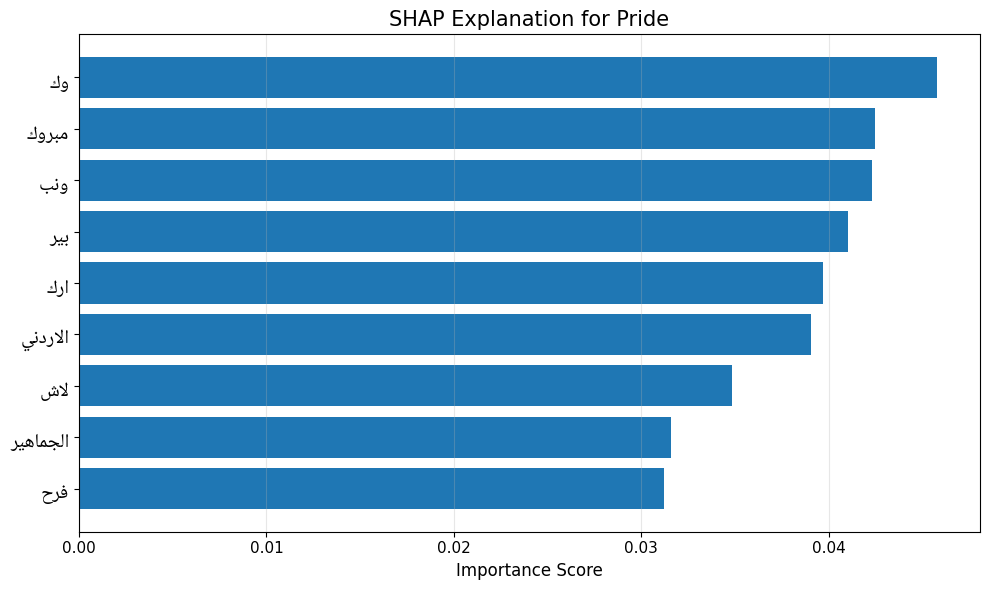


اكتب تعليق عربي ,أو اكتب خروج لإنهاء البرنامج: اصلا من اساسيات كره القدم ومن اساسيات اي مواجهه بين اي فريقين او منتخبين اللي هو احترام الخصم فاحترام الخصم يعتبر في كره القدم هو خمسين في المئه من فوزك في المباراه

TEXT: اصلا من اساسيات كره القدم ومن اساسيات اي مواجهه بين اي فريقين او منتخبين اللي هو احترام الخصم فاحترام الخصم يعتبر في كره القدم هو خمسين في المئه من فوزك في المباراه
CLEANED: اصلا من اساسيات كره القدم ومن اساسيات اي مواجهه بين اي فريقين او منتخبين اللي هو احترام الخصم فاحترام الخصم يعتبر في كره القدم هو خمسين في الميه من فوزك في المباراه
PREDICTION: Neutral
CONFIDENCE: 96.19 %
KEYWORDS: ['اللي']

SHAP EXPLANATION
TEXT: اصلا من اساسيات كره القدم ومن اساسيات اي مواجهه بين اي فريقين او منتخبين اللي هو احترام الخصم فاحترام الخصم يعتبر في كره القدم هو خمسين في المئه من فوزك في المباراه
CLEANED: اصلا من اساسيات كره القدم ومن اساسيات اي مواجهه بين اي فريقين او منتخبين اللي هو احترام الخصم فاحترام الخصم يعتبر في كره القدم هو خمسين في الميه من فوزك في المباراه
PREDICTION: Neutral

,token,shap_value
3,اساسيات,0.093739
7,اساسيات,0.054332
5,القدم,0.045815
20,احترام,0.043048
21,الخصم,0.039939
6,ومن,0.036776
39,المبار,0.029227
29,القدم,0.029100
13,فريق,0.027251
1,اصلا,-0.030856


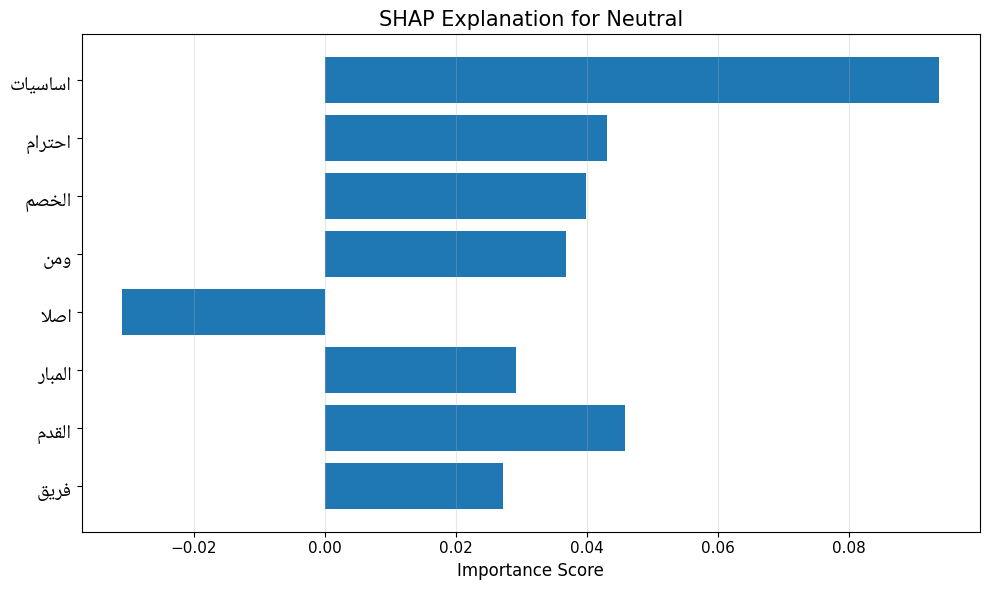


اكتب تعليق عربي ,أو اكتب خروج لإنهاء البرنامج: اليوم اني كلش ضايج راح اترك كل اللي كنا نتكلم عليه سابقا كريبتو شغلات راح احكي علي مباراه العراق والاردن لان اني مثل الهوايه مشجعين المنتخب منزعج من الخساره

TEXT: اليوم اني كلش ضايج راح اترك كل اللي كنا نتكلم عليه سابقا كريبتو شغلات راح احكي علي مباراه العراق والاردن لان اني مثل الهوايه مشجعين المنتخب منزعج من الخساره
CLEANED: اليوم اني كلش ضايج راح اترك كل اللي كنا نتكلم عليه سابقا كريبتو شغلات راح احكي علي مباراه العراق والاردن لان اني مثل الهوايه مشجعين المنتخب منزعج من الخساره
PREDICTION: Anger
CONFIDENCE: 87.85 %
KEYWORDS: ['العراق', 'الي']

SHAP EXPLANATION
TEXT: اليوم اني كلش ضايج راح اترك كل اللي كنا نتكلم عليه سابقا كريبتو شغلات راح احكي علي مباراه العراق والاردن لان اني مثل الهوايه مشجعين المنتخب منزعج من الخساره
CLEANED: اليوم اني كلش ضايج راح اترك كل اللي كنا نتكلم عليه سابقا كريبتو شغلات راح احكي علي مباراه العراق والاردن لان اني مثل الهوايه مشجعين المنتخب منزعج من الخساره
PREDICTION: Anger
CONFIDENCE: 87.85 %
EXPLAINING CLA

,token,shap_value
5,ضا,0.065728
15,سابقا,0.051848
8,اترك,0.050087
7,راح,0.046535
6,يج,0.045531
19,شغل,0.041151
40,الخس,0.040116
28,والاردن,-0.037157
34,مشج,-0.051216
1,اليوم,-0.087773


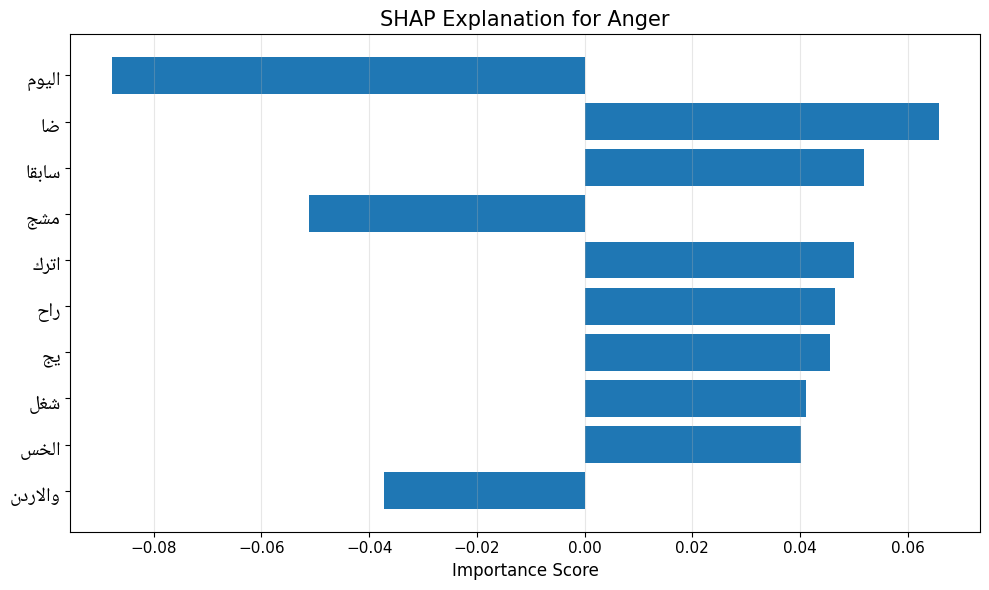


اكتب تعليق عربي ,أو اكتب خروج لإنهاء البرنامج: خروج
تم إنهاء البرنامج


In [ ]:
!pip install shap arabic-reshaper python-bidi -q > /dev/null 2>&1
!apt-get update -qq > /dev/null 2>&1
!apt-get install -y fonts-noto > /dev/null 2>&1

import torch
import numpy as np
import pandas as pd
import re
import shap
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import arabic_reshaper
import warnings

from bidi.algorithm import get_display
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings("ignore")



df = pd.read_csv("Jordan_Cleaned_Comments.csv")

df = df[["Cleaned_Comment", "Class"]].dropna()

df = df[df["Cleaned_Comment"].str.strip() != ""]



def clean_text(text):

    text = str(text)

    text = re.sub(r'[^\u0600-\u06FF\s]', ' ', text)

    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "و", text)
    text = re.sub("ئ", "ي", text)
    text = re.sub("ة", "ه", text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

df["clean"] = df["Cleaned_Comment"].apply(clean_text)


BEST_MAX_LEN = 128


arabic_stopwords = [
    "الاردن",
    "الله",
    "والله",
    "علي",
    "اليوم",
    "كاس",
    "العالم",
    "المنتخب",
    "منتخب",
    "الاردني",
    "جدا",
    "لازم",
    "الفريق",
    "المباراه",
    "مباراه",
    "كان",
    "كانت"
]

vectorizer = TfidfVectorizer(
    max_df=0.85,
    min_df=2,
    ngram_range=(1, 2),
    stop_words=arabic_stopwords
)

X = vectorizer.fit_transform(df["clean"])

features = np.array(
    vectorizer.get_feature_names_out()
)

emotion_keywords = {}

for emotion in df["Class"].unique():

    idx = (df["Class"].values == emotion)

    scores = X[idx].sum(axis=0).A1

    top_idx = scores.argsort()[::-1]

    words = features[top_idx]

    seen = set()

    final_words = []

    for w in words:

        w = w.strip()

        if len(w) < 2:
            continue

        if w in seen:
            continue

        seen.add(w)

        final_words.append(w)

        if len(final_words) == 15:
            break

    emotion_keywords[emotion] = final_words

print("\nSMART TF-IDF KEYWORDS\n")

for emotion, words in emotion_keywords.items():

    print(f"{emotion} --> {words}")


def predict_comment(text):

    cleaned = clean_text(text)

    inputs = tokenizer(
        cleaned,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=BEST_MAX_LEN
    )

    inputs = {
        k: v.to(best_trainer.model.device)
        for k, v in inputs.items()
    }

    best_trainer.model.eval()

    with torch.no_grad():

        outputs = best_trainer.model(**inputs)

    probs = torch.softmax(
        outputs.logits,
        dim=1
    ).cpu().numpy()[0]

    pred_id = np.argmax(probs)

    label = id2label[pred_id]

    confidence = probs[pred_id] * 100

    keywords = [
        w for w in emotion_keywords.get(label, [])
        if w in cleaned
    ]

    print("\n==============================")
    print("TEXT:", text)
    print("CLEANED:", cleaned)
    print("PREDICTION:", label)
    print("CONFIDENCE:", round(confidence, 2), "%")
    print("KEYWORDS:", keywords if keywords else "No strong keyword found")
    print("==============================")

    return {
        "text": text,
        "cleaned": cleaned,
        "prediction": label,
        "confidence": confidence,
        "keywords": keywords
    }


class_names = [
    id2label[i]
    for i in range(len(id2label))
]

def model_predict(texts):

    enc = tokenizer(
        list(texts),
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=BEST_MAX_LEN
    )

    enc = {
        k: v.to(best_trainer.model.device)
        for k, v in enc.items()
    }

    best_trainer.model.eval()

    with torch.no_grad():

        logits = best_trainer.model(**enc).logits

    probs = torch.softmax(
        logits,
        dim=1
    ).cpu().numpy()

    return probs


explainer = shap.Explainer(
    model_predict,
    tokenizer,
    output_names=class_names
)


arabic_font_path = "/usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf"

arabic_font = fm.FontProperties(
    fname=arabic_font_path
)


def fix_arabic(text):

    text = str(text)

    text = text.replace("##", "")
    text = text.replace("▁", "")
    text = text.strip()

    if text == "":
        return ""

    reshaped = arabic_reshaper.reshape(text)

    bidi_text = get_display(reshaped)

    return bidi_text


def clean_token(token):

    token = str(token)

    token = token.replace("##", "")
    token = token.replace("▁", "")

    token = token.replace("[CLS]", "")
    token = token.replace("[SEP]", "")
    token = token.replace("[PAD]", "")

    token = token.strip()

    return token


def explain_with_shap(text, target_label=None, top_n=10):

    cleaned = clean_text(text)

    shap_values = explainer([cleaned])

    probs = model_predict([cleaned])[0]

    pred_id = np.argmax(probs)

    pred_label = id2label[pred_id]

    if target_label is None:

        target_id = pred_id

        target_label = pred_label

    else:

        target_id = label2id[target_label]

    tokens = shap_values.data[0]

    values = shap_values.values[0][:, target_id]

    df_shap = pd.DataFrame({
        "token": tokens,
        "shap_value": values
    })

    df_shap["token"] = df_shap["token"].apply(clean_token)

    df_shap = df_shap[df_shap["token"] != ""]

    df_shap["abs_value"] = df_shap["shap_value"].abs()

    df_shap = df_shap.sort_values(
        "abs_value",
        ascending=True
    ).tail(top_n)

    print("\n==============================")
    print("SHAP EXPLANATION")
    print("TEXT:", text)
    print("CLEANED:", cleaned)
    print("PREDICTION:", pred_label)
    print("CONFIDENCE:", round(probs[pred_id] * 100, 2), "%")
    print("EXPLAINING CLASS:", target_label)
    print("==============================")

    display(
        df_shap[["token", "shap_value"]]
        .sort_values("shap_value", ascending=False)
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        [fix_arabic(t) for t in df_shap["token"]],
        df_shap["shap_value"]
    )

    plt.xlabel(
        "Importance Score",
        fontsize=12
    )

    plt.title(
        f"SHAP Explanation for {target_label}",
        fontsize=15
    )

    plt.yticks(
        fontproperties=arabic_font,
        fontsize=14
    )

    plt.xticks(fontsize=11)

    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()

    plt.show()


while True:

    text = input(
        "\nاكتب تعليق عربي ,أو اكتب خروج لإنهاء البرنامج: "
    )

    if text.strip() == "خروج":

        print("تم إنهاء البرنامج")

        break

    if text.strip() == "":

        print("الرجاء إدخال تعليق غير فارغ")

        continue

    predict_comment(text)

    explain_with_shap(text)